In [ ]:
DATA_ROOT   = 'E:/.MSc/Research/Data'  # Folder containing 59146237, 59146238, 59146239
OUTPUT_DIR  = './output'


import os
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f'DATA_ROOT  : {DATA_ROOT}')
print(f'OUTPUT_DIR : {OUTPUT_DIR}')

DATA_ROOT  : E:/.MSc/Research/Data
OUTPUT_DIR : ./output


## 1. Imports & Setup

In [ ]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')


# Plot style
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11
})


EXPERIMENT_FOLDERS = ['59146237', '59146238', '59146239']

# All expected HDF5 groups and their meaning
SIGNAL_MAP = {
    '_030': 'ECG_Niccomo',       '_031': 'ICG_raw_Z',
    '_032': 'Rpeaks_Niccomo',    '_033': 'AVO_Niccomo',
    '_034': 'PEP_Niccomo',       '_035': 'AVC_Niccomo',
    '_036': 'LVET_Niccomo',
    '_060': 'ECG_Stethoscope',   '_061': 'PCG',
    '_062': 'Rpeaks_Stetho',     '_063': 'AVO_Stetho',
    '_064': 'PEP_Stetho',        '_065': 'AVC_Stetho',
    '_066': 'LVET_Stetho',
    '_090': 'ECG_Echo',          '_091': 'ECHO_image',
    '_092': 'Rpeaks_Echo',       '_093': 'AVO_Echo_GT',
    '_094': 'PEP_Echo_GT',       '_095': 'AVC_Echo_GT',
    '_096': 'LVET_Echo_GT',
    '_120': 'ECG_PPG',           '_121': 'PPG',
    '_122': 'Rpeaks_PPG',        '_123': 'AVO_PPG',
    '_124': 'PEP_PPG',           '_125': 'AVC_PPG',
    '_126': 'LVET_PPG',
}

# The 6 critical signals needed for model
CRITICAL = ['_031', '_030', '_093', '_094', '_095', '_096']

print(f'   Total expected signal groups: {len(SIGNAL_MAP)}')
print(f'   Critical signals required:    {len(CRITICAL)}')

    Imports complete
   Total expected signal groups: 28
   Critical signals required:    6


## 2. File System Scan — What Do We Have?

In [3]:
data_root = Path(DATA_ROOT)

# Scan all 3 experiment folders
all_files = []
for exp in EXPERIMENT_FOLDERS:
    exp_dir = data_root / exp / 'measure'
    if not exp_dir.exists():
        print(f'⚠️  Not found: {exp_dir}')
        continue
    files = sorted(exp_dir.glob('*.h5'))
    for f in files:
        parts = f.stem.split('_')
        all_files.append({
            'filepath':   str(f),
            'filename':   f.name,
            'experiment': exp,
            'subject_id': f'CHC{parts[0][2:]}' if len(parts) >= 1 and parts[0].startswith('CH') else (parts[0] if len(parts) >= 1 else 'UNK'),
            'date_token': parts[1] if len(parts) >= 2 else 'UNK',
            'record_id':  parts[2] if len(parts) >= 3 else 'UNK',
        })
    print(f'  Experiment {exp}: {len(files):3d} files')

files_df = pd.DataFrame(all_files)
print(f'\n Total files found: {len(files_df)}')
print(f'   Unique subjects:   {files_df["subject_id"].nunique()}')
files_df.head(5)

  Experiment 59146237:  37 files
  Experiment 59146238:  83 files
  Experiment 59146239:  92 files

 Total files found: 212
   Unique subjects:   17


,filepath,filename,experiment,subject_id,date_token,record_id
0,E:\.MSc\Research\Data\59146237\measure\CH07_59...,CH07_59146237_s0000029.h5,59146237,CHC07,59146237,s0000029
1,E:\.MSc\Research\Data\59146237\measure\CH07_59...,CH07_59146237_s0000030.h5,59146237,CHC07,59146237,s0000030
2,E:\.MSc\Research\Data\59146237\measure\CH07_59...,CH07_59146237_s0000031.h5,59146237,CHC07,59146237,s0000031
3,E:\.MSc\Research\Data\59146237\measure\CH07_59...,CH07_59146237_s0000032.h5,59146237,CHC07,59146237,s0000032
4,E:\.MSc\Research\Data\59146237\measure\CH07_59...,CH07_59146237_s0000033.h5,59146237,CHC07,59146237,s0000033


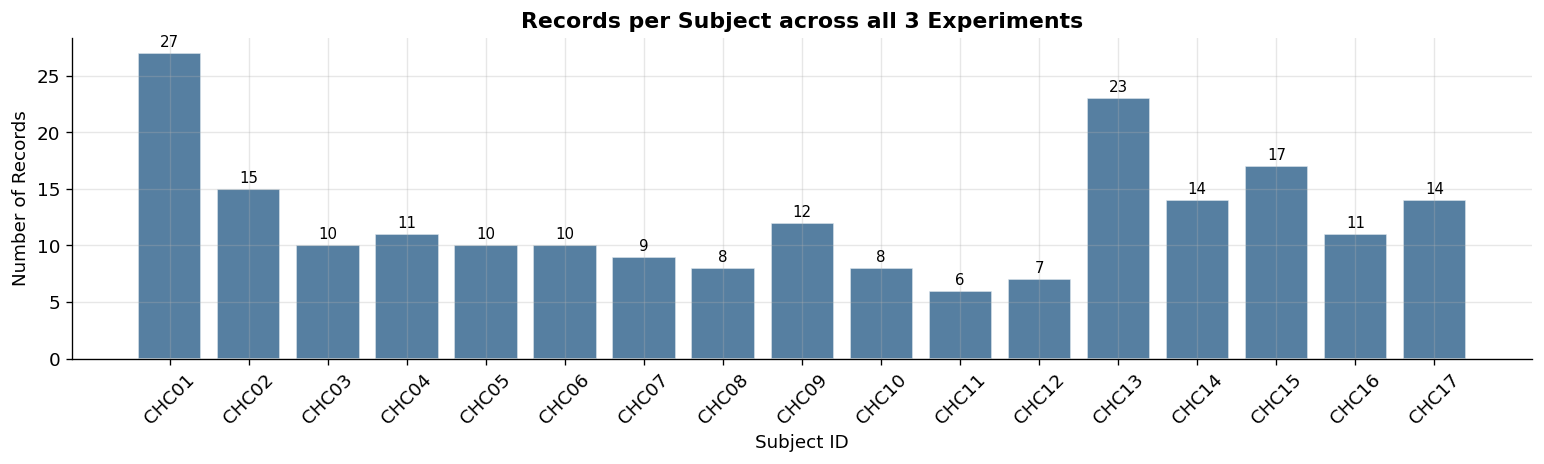


Min records per subject: 6 | Max: 27 | Mean: 12.5


In [4]:
# Records per subject
rps = files_df.groupby('subject_id').size().reset_index(name='n_records')

fig, ax = plt.subplots(figsize=(13, 4))
colors = ['#2C5F8A' if s.startswith('CH') else '#888' for s in rps['subject_id']]
ax.bar(rps['subject_id'], rps['n_records'], color='#2C5F8A', alpha=0.8, edgecolor='white')
ax.set_xlabel('Subject ID')
ax.set_ylabel('Number of Records')
ax.set_title('Records per Subject across all 3 Experiments', fontweight='bold')
for i, (s, n) in enumerate(zip(rps['subject_id'], rps['n_records'])):
    ax.text(i, n + 0.3, str(n), ha='center', va='bottom', fontsize=9)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
print(f'\nMin records per subject: {rps["n_records"].min()} | Max: {rps["n_records"].max()} | Mean: {rps["n_records"].mean():.1f}')

## 3. Deep-Dive into HDF5 File Structure
Let's open one file and understand its exact internal layout before doing bulk analysis.

In [5]:
# Open the first available file and print its full tree
sample_path = files_df.iloc[0]['filepath']
print(f'📂 Opening: {Path(sample_path).name}\n')

def print_hdf5_tree(name, obj, indent=0):
    prefix = '  ' * indent
    if isinstance(obj, h5py.Dataset):
        print(f'{prefix}📄 {name.split("/")[-1]}  shape={obj.shape}  dtype={obj.dtype}')
    elif isinstance(obj, h5py.Group):
        print(f'{prefix}📁 {name.split("/")[-1]}/')

with h5py.File(sample_path, 'r') as f:
    print('Top-level keys:', list(f.keys()))
    measure_keys = list(f['measure']['value'].keys())
    print(f'\nGroups inside measure/value: {len(measure_keys)} groups')
    print('Groups:', measure_keys[:10], '...' if len(measure_keys) > 10 else '')
    
    print('\n--- First group detail (_030 = ECG Niccomo) ---')
    grp = f['measure']['value']['_030']['value']
    print('Sub-keys:', list(grp.keys()))
    for k in grp.keys():
        item = grp[k]
        if isinstance(item, h5py.Dataset):
            print(f'  {k}: shape={item.shape} dtype={item.dtype}')

📂 Opening: CH07_59146237_s0000029.h5

Top-level keys: ['measure']

Groups inside measure/value: 151 groups
Groups: ['_000', '_001', '_002', '_003', '_004', '_005', '_006', '_007', '_008', '_009'] ...

--- First group detail (_030 = ECG Niccomo) ---
Sub-keys: ['Bits', 'Calibration', 'Flipped', 'Gain', 'HwCh', 'Offset', 'Rate', 'Resolution', 'Unit', 'amp', 'data', 'label', 'pfad', 'time']


In [6]:
# -------------------------------------------------------
# CANONICAL ACCESS PATTERN FOR ALL SIGNALS
# This is the standard way to read any continuous signal:
# -------------------------------------------------------
with h5py.File(sample_path, 'r') as f:
    
    # --- ECG (group _030) ---
    ecg_raw  = f['measure']['value']['_030']['value']['data']['value'][()]
    ecg_time = f['measure']['value']['_030']['value']['time']['value'][()]
    
    # Flatten from (1, N) → (N,)  [all continuous signals are 2D]
    ecg  = ecg_raw[0]  if ecg_raw.ndim == 2  else ecg_raw
    t_ecg = ecg_time[0] if ecg_time.ndim == 2 else ecg_time

    # --- ICG raw Z (group _031) ---
    icg_raw  = f['measure']['value']['_031']['value']['data']['value'][()]
    icg_time = f['measure']['value']['_031']['value']['time']['value'][()]
    icg  = icg_raw[0]  if icg_raw.ndim == 2  else icg_raw
    t_icg = icg_time[0] if icg_time.ndim == 2 else icg_time

    # --- AVO_Echo (group _093) — EVENT timestamps (1D, not 2D!) ---
    avo_echo = f['measure']['value']['_093']['value']['data']['value'][()].flatten()

    # --- PEP_Echo (group _094) — interval array in ms ---
    pep_echo = f['measure']['value']['_094']['value']['data']['value'][()].flatten()

    # --- AVC_Echo (group _095) ---
    avc_echo = f['measure']['value']['_095']['value']['data']['value'][()].flatten()

    # --- LVET_Echo (group _096) ---
    lvet_echo = f['measure']['value']['_096']['value']['data']['value'][()].flatten()

print('Signal shapes from sample file:')
print(f'  ECG:       {ecg.shape}  | time range: {t_ecg[0]:.0f}–{t_ecg[-1]:.0f} ms  | fs≈{1000/np.mean(np.diff(t_ecg)):.0f} Hz')
print(f'  ICG raw Z: {icg.shape}  | time range: {t_icg[0]:.0f}–{t_icg[-1]:.0f} ms  | fs≈{1000/np.mean(np.diff(t_icg)):.0f} Hz')
print(f'  AVO_Echo:  {avo_echo.shape}  (beat timestamps in ms)')
print(f'  PEP_Echo:  {pep_echo.shape}  values: {pep_echo[:5]} ms')
print(f'  AVC_Echo:  {avc_echo.shape}')
print(f'  LVET_Echo: {lvet_echo.shape}  values: {lvet_echo[:5]} ms')

Signal shapes from sample file:
  ECG:       (1625,)  | time range: 0–8 ms  | fs≈201783 Hz
  ICG raw Z: (1625,)  | time range: 0–8 ms  | fs≈201783 Hz
  AVO_Echo:  (2,)  (beat timestamps in ms)
  PEP_Echo:  (2,)  values: [0 0] ms
  AVC_Echo:  (2,)
  LVET_Echo: (2,)  values: [0 0] ms


## 4. The Special Case: ECHO Signal (_091)
The ECHO group has a **3D array** — fundamentally different from all other signals.

ECHO raw shape: (3, 1096, 274)
ECHO time shape: (1, 1096)
Dimensions: axis0=channels(3), axis1=time, axis2=depth_or_velocity

Depth/velocity dimension size: 274 → Likely: M-mode (depth vs time)


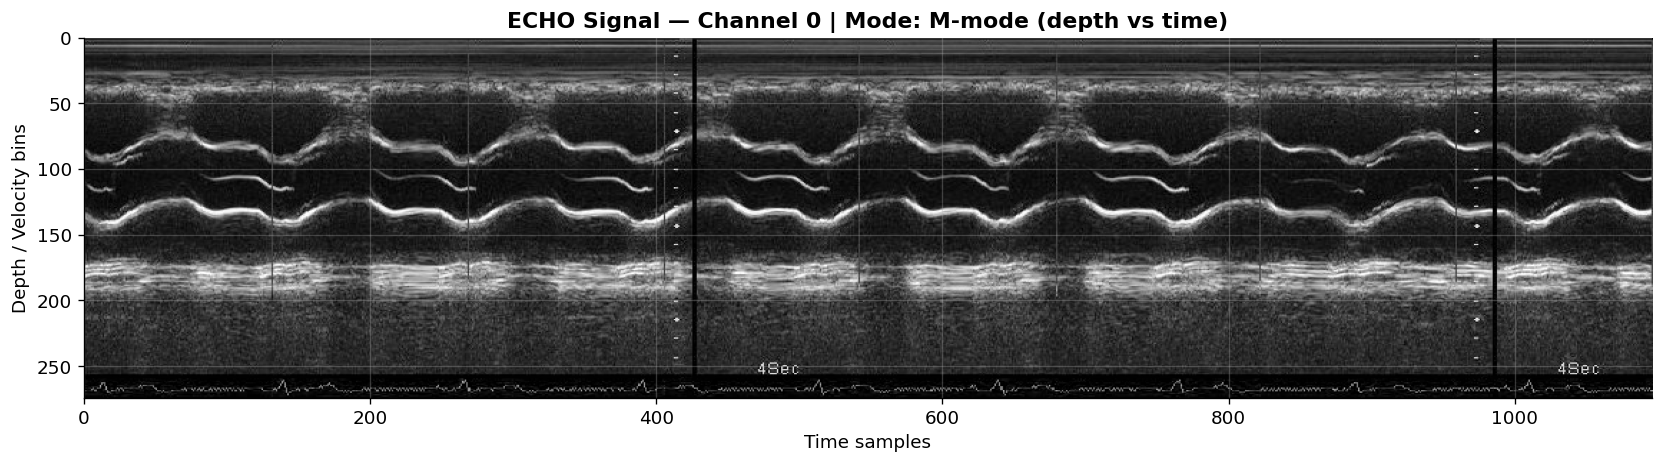

In [7]:
with h5py.File(sample_path, 'r') as f:
    try:
        echo_raw = f['measure']['value']['_091']['value']['data']['value'][()]
        echo_time = f['measure']['value']['_091']['value']['time']['value'][()]
        print(f'ECHO raw shape: {echo_raw.shape}')
        print(f'ECHO time shape: {echo_time.shape}')
        print(f'Dimensions: axis0=channels(3), axis1=time, axis2=depth_or_velocity')
        
        # The paper says: first dim=channel, second=time, third=depth/velocity
        # To visualize: take channel 0, transpose so time is on x-axis
        echo_ch0 = echo_raw[0, :, :].T   # shape: (depth, time)
        
        # Determine mode
        depth_dim = echo_raw.shape[2]
        mode = 'M-mode (depth vs time)' if depth_dim > 100 else 'Doppler (velocity vs time)'
        print(f'\nDepth/velocity dimension size: {depth_dim} → Likely: {mode}')
        
        # Visualize channel 0
        fig, ax = plt.subplots(figsize=(14, 4))
        ax.imshow(echo_ch0, aspect='auto', cmap='gray', 
                  extent=[0, echo_ch0.shape[1], echo_ch0.shape[0], 0])
        ax.set_title(f'ECHO Signal — Channel 0 | Mode: {mode}', fontweight='bold')
        ax.set_xlabel('Time samples')
        ax.set_ylabel('Depth / Velocity bins')
        plt.tight_layout()
        plt.show()
        
    except KeyError:
        print('⚠️  ECHO (_091) not present in this file — may be in a different experiment')

## 5. Visualize Raw Signals
Let's see what ECG and ICG look like before any processing.

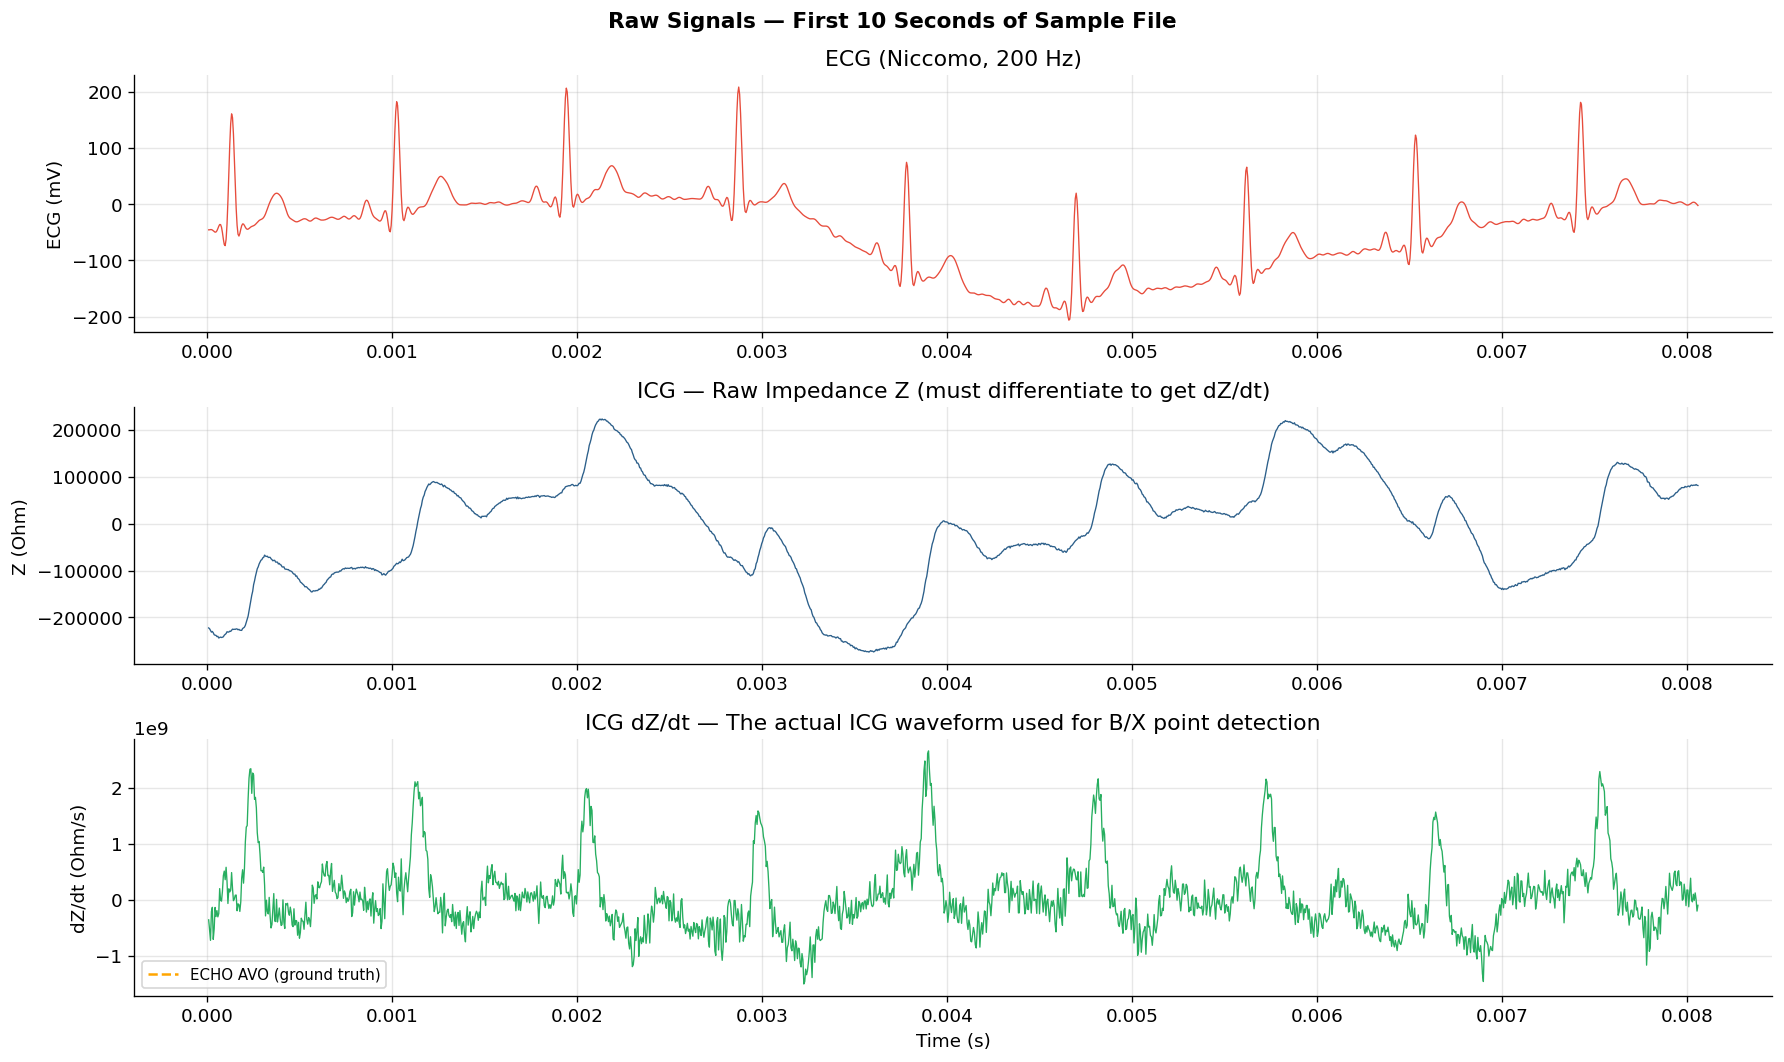

In [8]:
# Compute dZ/dt from raw ICG
dt_s = np.mean(np.diff(t_icg)) / 1000.0   # ms → s
dzdt = np.gradient(icg, dt_s)

# Show first 10 seconds
mask = t_ecg < (t_ecg[0] + 10000)   # 10,000 ms = 10 s
mask_icg = t_icg < (t_icg[0] + 10000)

fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=False)
fig.suptitle('Raw Signals — First 10 Seconds of Sample File', fontsize=13, fontweight='bold')

axes[0].plot(t_ecg[mask] / 1000, ecg[mask], color='#E74C3C', linewidth=0.8)
axes[0].set_ylabel('ECG (mV)')
axes[0].set_title('ECG (Niccomo, 200 Hz)')

axes[1].plot(t_icg[mask_icg] / 1000, icg[mask_icg], color='#2C5F8A', linewidth=0.8)
axes[1].set_ylabel('Z (Ohm)')
axes[1].set_title('ICG — Raw Impedance Z (must differentiate to get dZ/dt)')

axes[2].plot(t_icg[mask_icg] / 1000, dzdt[mask_icg], color='#27AE60', linewidth=0.8)
# Overlay AVO (valve opening) markers if available
if len(avo_echo) > 0:
    avo_in_range = avo_echo[(avo_echo >= t_icg[0]) & (avo_echo < t_icg[0] + 10000)]
    for a in avo_in_range:
        axes[2].axvline(a/1000, color='orange', alpha=0.7, linewidth=1.5, linestyle='--')
    axes[2].plot([], [], color='orange', linestyle='--', linewidth=1.5, label='ECHO AVO (ground truth)')
    axes[2].legend(fontsize=9)
axes[2].set_ylabel('dZ/dt (Ohm/s)')
axes[2].set_title('ICG dZ/dt — The actual ICG waveform used for B/X point detection')
axes[2].set_xlabel('Time (s)')

plt.tight_layout()
plt.show()

## 6. Bulk Quality Audit — All 208 Files

In [9]:
def audit_one_file(filepath):
    """Check a single HDF5 file for signal presence and basic stats."""
    rec = {'filepath': str(filepath), 'loadable': False}
    try:
        with h5py.File(filepath, 'r') as f:
            rec['loadable'] = True
            groups = list(f['measure']['value'].keys())
            rec['n_groups'] = len(groups)
            
            # Check each critical signal
            for gid in CRITICAL:
                try:
                    shape = f['measure']['value'][gid]['value']['data']['value'].shape
                    rec[f'has{gid}'] = True
                    rec[f'shape{gid}'] = str(shape)
                except Exception:
                    rec[f'has{gid}'] = False
                    rec[f'shape{gid}'] = 'absent'
            
            # Check for PPG
            try:
                f['measure']['value']['_121']['value']['data']['value']
                rec['has_ppg'] = True
            except Exception:
                rec['has_ppg'] = False
            
            # Duration from ECG time vector
            try:
                t = f['measure']['value']['_030']['value']['time']['value'][()]
                t = t[0] if t.ndim == 2 else t
                rec['duration_sec'] = float(t[-1] - t[0]) / 1000
                rec['n_samples'] = len(t)
            except Exception:
                rec['duration_sec'] = None
                rec['n_samples'] = None
            
            # Beat count from AVO_Echo
            try:
                avo = f['measure']['value']['_093']['value']['data']['value'][()].flatten()
                rec['n_beats_echo'] = len(avo)
            except Exception:
                rec['n_beats_echo'] = 0
                
    except Exception as e:
        rec['error'] = str(e)
    
    rec['complete'] = all(rec.get(f'has{gid}', False) for gid in CRITICAL)
    return rec

print('Running bulk audit across all files...')
print('(This may take a few minutes for 208 files)\n')

audit_records = []
for i, row in files_df.iterrows():
    rec = audit_one_file(row['filepath'])
    rec.update({'subject_id': row['subject_id'], 'experiment': row['experiment'],
                'record_id': row['record_id'], 'filename': row['filename']})
    audit_records.append(rec)
    if (i + 1) % 50 == 0:
        print(f'  Audited {i+1}/{len(files_df)} files...')

audit_df = pd.DataFrame(audit_records)

# Save manifest
audit_df.to_csv(f'{OUTPUT_DIR}/master_manifest.csv', index=False)
print(f'\n✅ Audit complete! Saved master_manifest.csv')
print(f'   Total files:     {len(audit_df)}')
print(f'   Loadable:        {audit_df["loadable"].sum()}')
print(f'   Complete (all 6 critical signals): {audit_df["complete"].sum()}')
print(f'   Has PPG:         {audit_df["has_ppg"].sum()} (experiment 59146237 only)')

Running bulk audit across all files...
(This may take a few minutes for 208 files)

  Audited 50/212 files...
  Audited 100/212 files...
  Audited 150/212 files...
  Audited 200/212 files...

✅ Audit complete! Saved master_manifest.csv
   Total files:     212
   Loadable:        212
   Complete (all 6 critical signals): 212
   Has PPG:         37 (experiment 59146237 only)


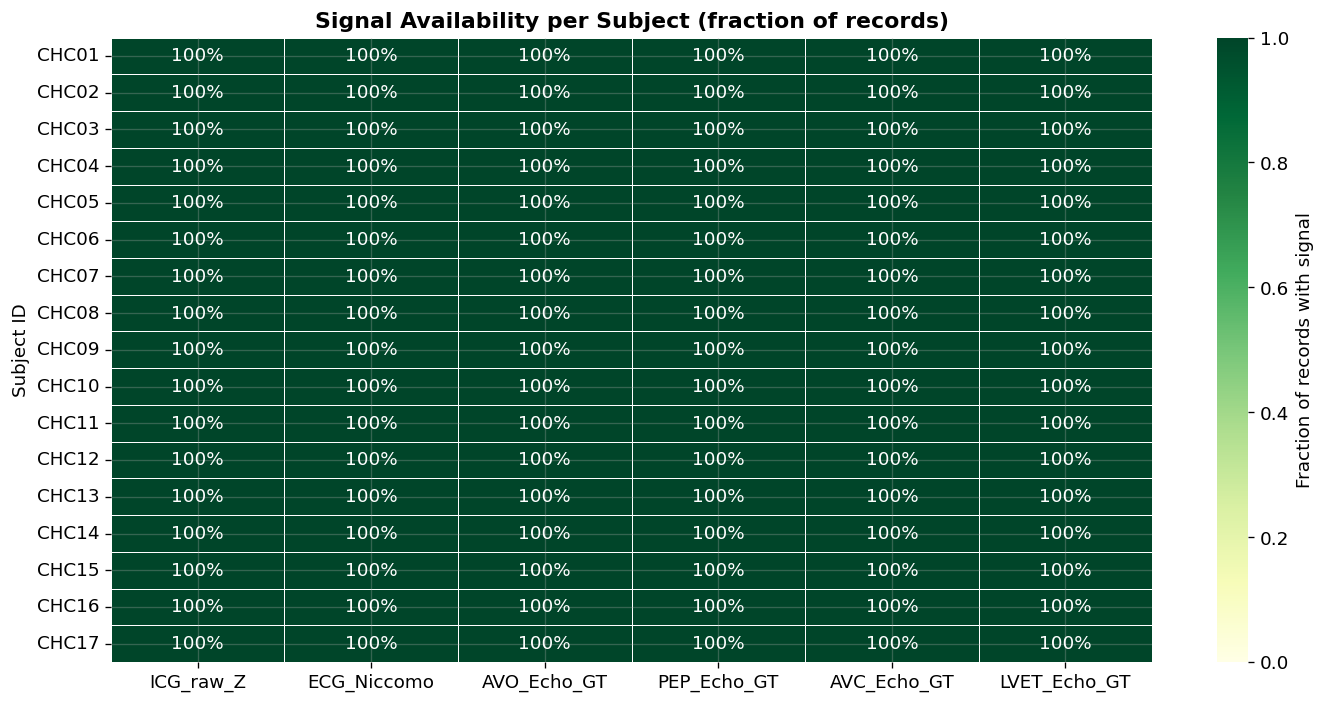

In [10]:
# Heatmap: signal availability per subject
has_cols = [f'has{gid}' for gid in CRITICAL]
col_labels = [SIGNAL_MAP.get(gid, gid) for gid in CRITICAL]

subj_availability = audit_df.groupby('subject_id')[has_cols].mean()
subj_availability.columns = col_labels

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(subj_availability, annot=True, fmt='.0%', cmap='YlGn', 
            linewidths=0.5, ax=ax, vmin=0, vmax=1,
            cbar_kws={'label': 'Fraction of records with signal'})
ax.set_title('Signal Availability per Subject (fraction of records)', fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('Subject ID')
plt.tight_layout()
plt.show()

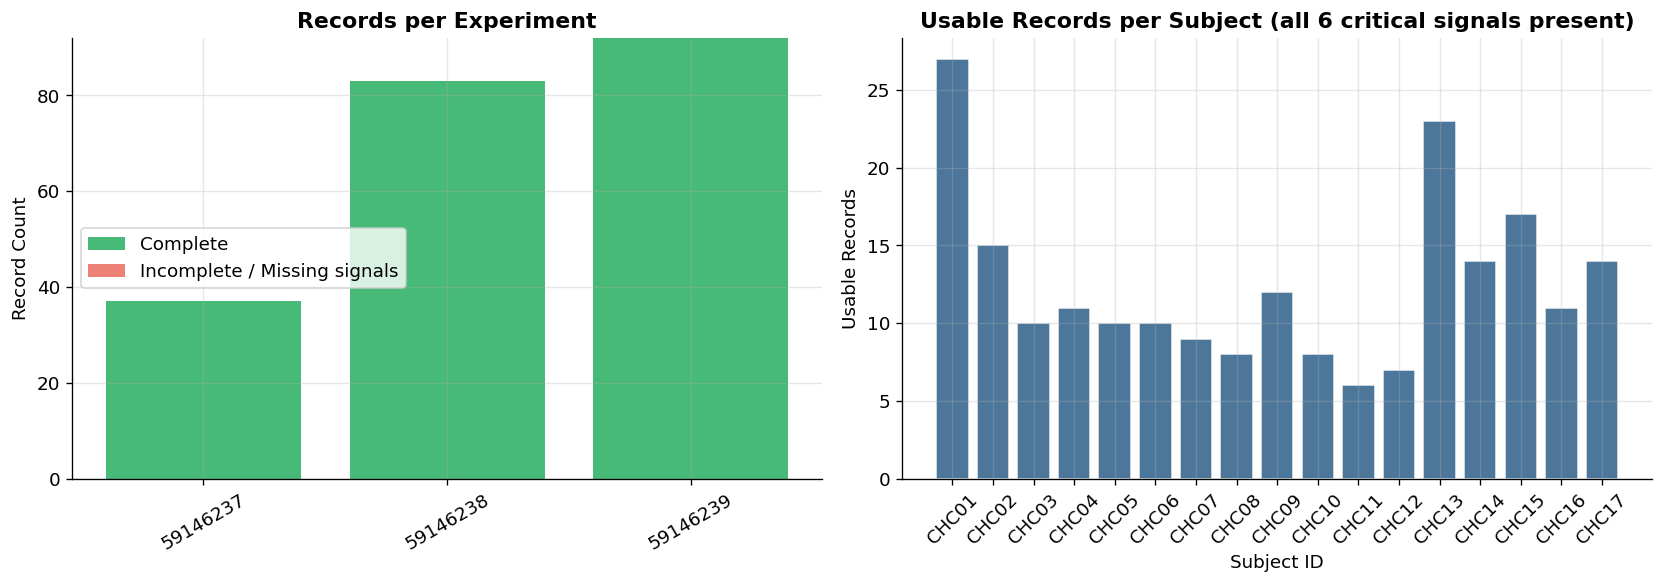

Total usable records: 212 out of 212 (100.0%)


In [11]:
# Completeness by experiment and subject
complete_df = audit_df[audit_df['complete']]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# By experiment
exp_counts = audit_df.groupby('experiment').agg(
    total=('complete', 'count'),
    complete=('complete', 'sum')
).reset_index()
exp_counts['incomplete'] = exp_counts['total'] - exp_counts['complete']

x = range(len(exp_counts))
axes[0].bar(x, exp_counts['complete'], label='Complete', color='#27AE60', alpha=0.85)
axes[0].bar(x, exp_counts['incomplete'], bottom=exp_counts['complete'], 
            label='Incomplete / Missing signals', color='#E74C3C', alpha=0.7)
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(exp_counts['experiment'], rotation=30)
axes[0].set_title('Records per Experiment', fontweight='bold')
axes[0].set_ylabel('Record Count')
axes[0].legend()

# By subject
subj_complete = complete_df.groupby('subject_id').size()
axes[1].bar(subj_complete.index, subj_complete.values, color='#2C5F8A', alpha=0.85, edgecolor='white')
axes[1].set_title('Usable Records per Subject (all 6 critical signals present)', fontweight='bold')
axes[1].set_xlabel('Subject ID')
axes[1].set_ylabel('Usable Records')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()
print(f'Total usable records: {len(complete_df)} out of {len(audit_df)} ({100*len(complete_df)/len(audit_df):.1f}%)')

## 7. Signal Duration Analysis

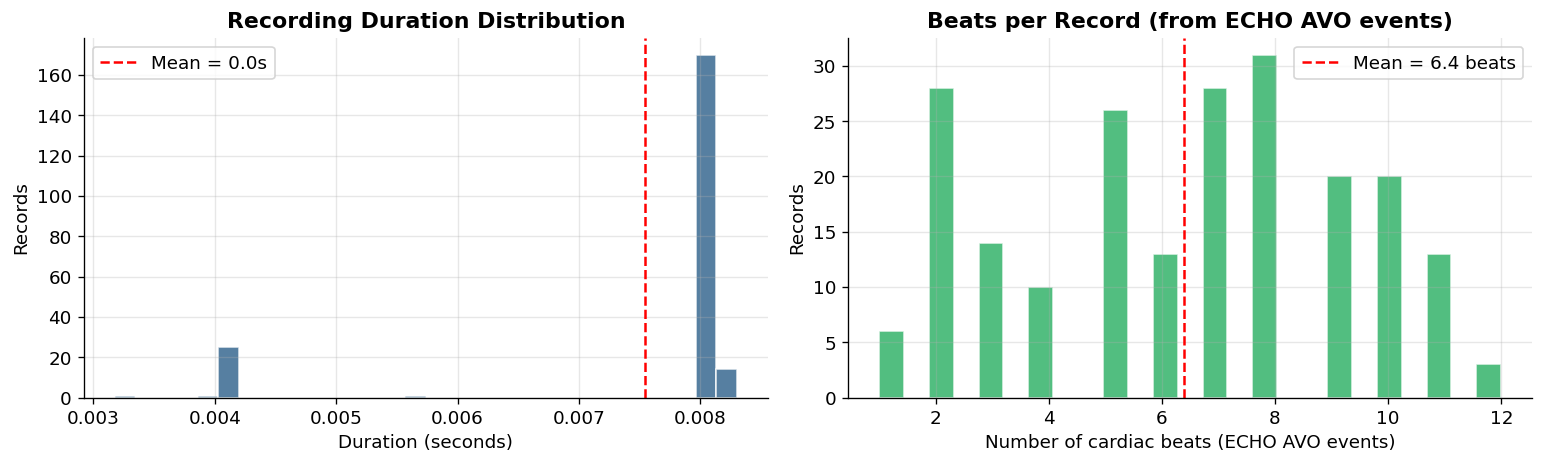


📊 Dataset Summary:
   Total usable records:          212
   Total ECHO-annotated beats:    1355
   Avg duration per record:       0.0s
   Avg beats per record:          6.4


In [12]:
dur_df = complete_df.dropna(subset=['duration_sec'])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(dur_df['duration_sec'], bins=30, color='#2C5F8A', alpha=0.8, edgecolor='white')
axes[0].axvline(dur_df['duration_sec'].mean(), color='red', linestyle='--', 
                label=f'Mean = {dur_df["duration_sec"].mean():.1f}s')
axes[0].set_xlabel('Duration (seconds)')
axes[0].set_ylabel('Records')
axes[0].set_title('Recording Duration Distribution', fontweight='bold')
axes[0].legend()

beats_df = complete_df.dropna(subset=['n_beats_echo'])
axes[1].hist(beats_df['n_beats_echo'], bins=25, color='#27AE60', alpha=0.8, edgecolor='white')
axes[1].axvline(beats_df['n_beats_echo'].mean(), color='red', linestyle='--',
                label=f'Mean = {beats_df["n_beats_echo"].mean():.1f} beats')
axes[1].set_xlabel('Number of cardiac beats (ECHO AVO events)')
axes[1].set_ylabel('Records')
axes[1].set_title('Beats per Record (from ECHO AVO events)', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

total_beats = int(beats_df['n_beats_echo'].sum())
print(f'\n📊 Dataset Summary:')
print(f'   Total usable records:          {len(complete_df)}')
print(f'   Total ECHO-annotated beats:    {total_beats}')
print(f'   Avg duration per record:       {dur_df["duration_sec"].mean():.1f}s')
print(f'   Avg beats per record:          {beats_df["n_beats_echo"].mean():.1f}')

## 8. Subject Demographics

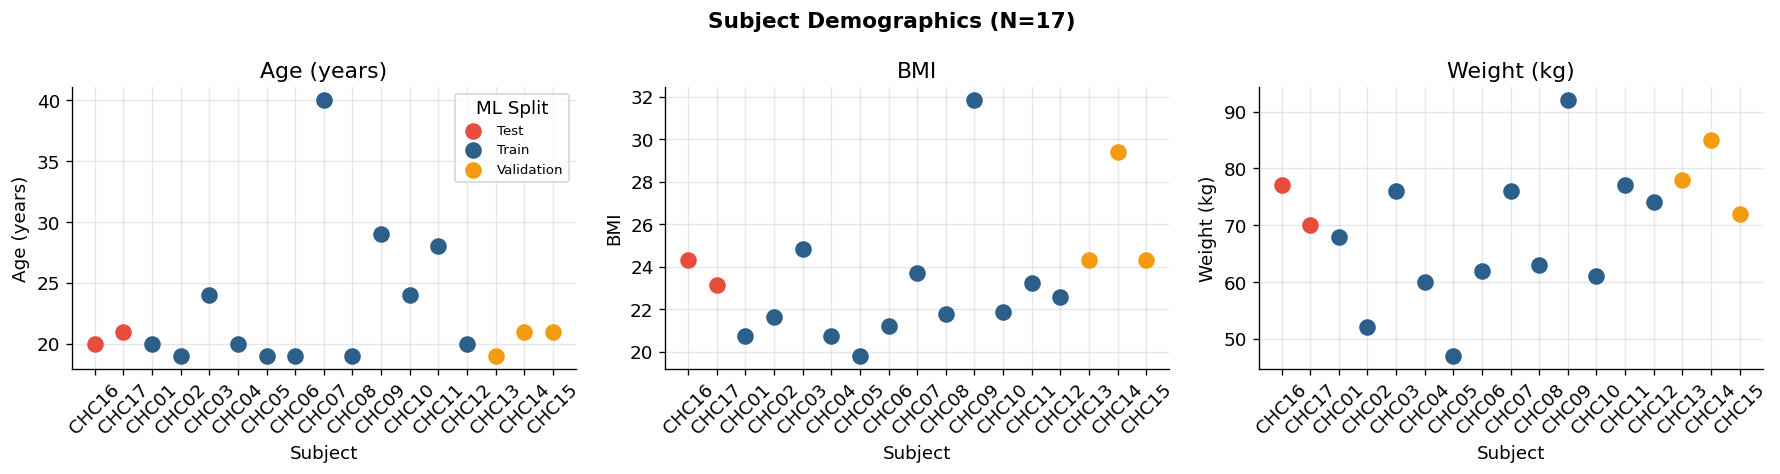


Split summary:
  Test        : ['CHC16', 'CHC17']
  Train       : ['CHC01', 'CHC02', 'CHC03', 'CHC04', 'CHC05', 'CHC06', 'CHC07', 'CHC08', 'CHC09', 'CHC10', 'CHC11', 'CHC12']
  Validation  : ['CHC13', 'CHC14', 'CHC15']


In [13]:
# Demographics from paper (Table 2)
demographics = pd.DataFrame([
    ('CHC01', 20, 181, 68, 'M', 20.76, '59146238'),
    ('CHC02', 19, 155, 52, 'F', 21.63, '59146238'),
    ('CHC03', 24, 175, 76, 'M', 24.82, '59146238'),
    ('CHC04', 20, 170, 60, 'F', 20.76, '59146238'),
    ('CHC05', 19, 154, 47, 'F', 19.81, '59146238'),
    ('CHC06', 19, 171, 62, 'M', 21.20, '59146238'),
    ('CHC07', 40, 179, 76, 'M', 23.72, '59146238'),
    ('CHC08', 19, 170, 63, 'M', 21.80, '59146238'),
    ('CHC09', 29, 170, 92, 'M', 31.83, '59146238'),
    ('CHC10', 24, 167, 61, 'M', 21.87, '59146238'),
    ('CHC11', 28, 182, 77, 'M', 23.25, '59146239'),
    ('CHC12', 20, 181, 74, 'M', 22.59, '59146239'),
    ('CHC13', 19, 179, 78, 'M', 24.34, '59146239'),
    ('CHC14', 21, 170, 85, 'M', 29.41, '59146239'),
    ('CHC15', 21, 172, 72, 'M', 24.34, '59146239'),
    ('CHC16', 20, 178, 77, 'M', 24.30, '59146239'),
    ('CHC17', 21, 174, 70, 'M', 23.12, '59146239'),
], columns=['subject_id', 'age', 'height_cm', 'weight_kg', 'gender', 'bmi', 'experiment'])

# Label ML split
def get_split(sid):
    n = int(sid.replace('CHC',''))
    if n <= 12: return 'Train'
    elif n <= 15: return 'Validation'
    else: return 'Test'
demographics['ml_split'] = demographics['subject_id'].apply(get_split)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Subject Demographics (N=17)', fontsize=13, fontweight='bold')

split_colors = {'Train': '#2C5F8A', 'Validation': '#F39C12', 'Test': '#E74C3C'}
for ax, col, label in [
    (axes[0], 'age',    'Age (years)'),
    (axes[1], 'bmi',    'BMI'),
    (axes[2], 'weight_kg', 'Weight (kg)'),
]:
    for split, grp in demographics.groupby('ml_split'):
        ax.scatter(grp['subject_id'], grp[col], c=split_colors[split], 
                   label=split, s=80, zorder=5)
    ax.set_xlabel('Subject')
    ax.set_ylabel(label)
    ax.set_title(label)
    ax.tick_params(axis='x', rotation=45)
axes[0].legend(title='ML Split', fontsize=8)
plt.tight_layout()
plt.show()

print('\nSplit summary:')
for split, grp in demographics.groupby('ml_split'):
    print(f"  {split:12s}: {list(grp['subject_id'].values)}")

## 9. Preview Ground Truth Labels

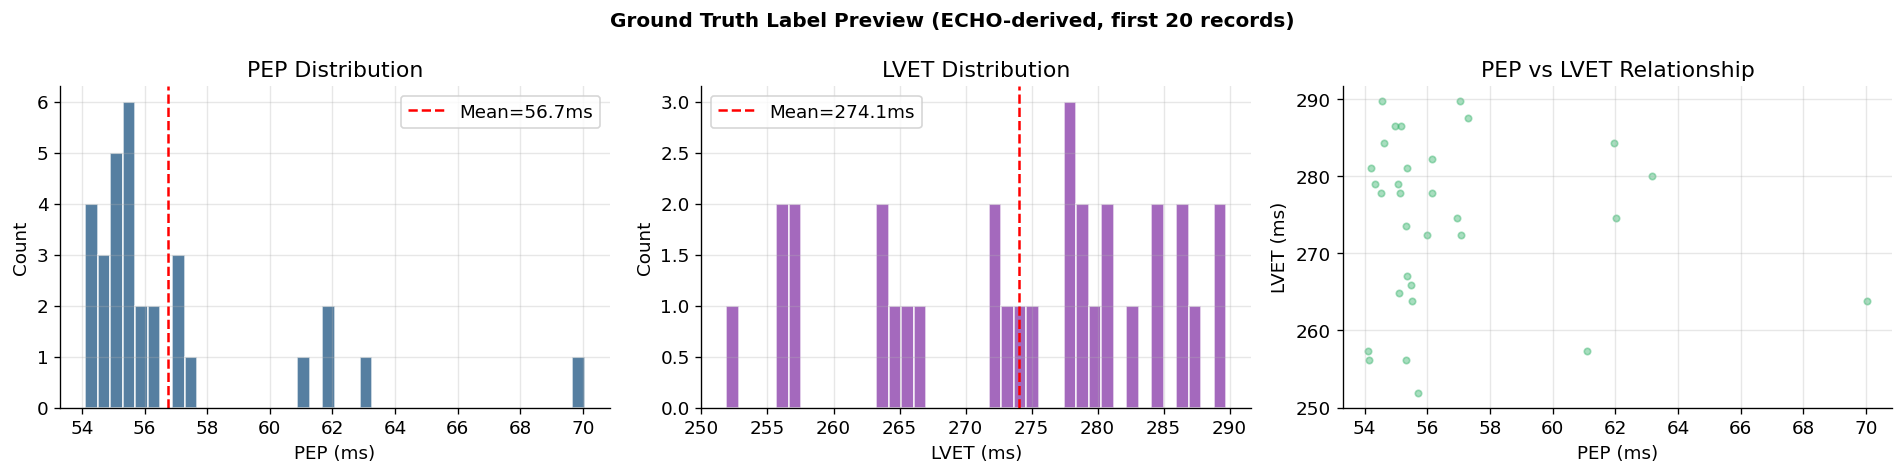


PEP  — Mean: 56.7 ± 3.4 ms | Range: [54, 70]
LVET — Mean: 274.1 ± 10.8 ms | Range: [252, 290]


In [14]:
# Load PEP and LVET from a sample of usable records
all_pep, all_lvet, all_subjects = [], [], []

sample_complete = complete_df.head(20)  # First 20 complete records

for _, row in sample_complete.iterrows():
    try:
        with h5py.File(row['filepath'], 'r') as f:
            pep  = f['measure']['value']['_094']['value']['data']['value'][()].flatten()
            lvet = f['measure']['value']['_096']['value']['data']['value'][()].flatten()
            # Filter physiological range
            pep_valid  = pep[(pep > 50) & (pep < 250)]
            lvet_valid = lvet[(lvet > 150) & (lvet < 500)]
            # Only add paired values to avoid mismatched lengths
            n_pairs = min(len(pep_valid), len(lvet_valid))
            if n_pairs > 0:
                all_pep.extend(pep_valid[:n_pairs].tolist())
                all_lvet.extend(lvet_valid[:n_pairs].tolist())
                all_subjects.extend([row['subject_id']] * n_pairs)
    except Exception:
        pass

all_pep = np.array(all_pep)
all_lvet = np.array(all_lvet)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('Ground Truth Label Preview (ECHO-derived, first 20 records)', fontsize=12, fontweight='bold')

# PEP histogram
axes[0].hist(all_pep, bins=40, color='#2C5F8A', alpha=0.8, edgecolor='white')
if all_pep.size > 0:
    axes[0].axvline(np.mean(all_pep), color='red', linestyle='--', label=f'Mean={np.mean(all_pep):.1f}ms')
axes[0].set_xlabel('PEP (ms)')
axes[0].set_ylabel('Count')
axes[0].set_title('PEP Distribution')
if all_pep.size > 0:
    axes[0].legend()

# LVET histogram
axes[1].hist(all_lvet, bins=40, color='#8E44AD', alpha=0.8, edgecolor='white')
if all_lvet.size > 0:
    axes[1].axvline(np.mean(all_lvet), color='red', linestyle='--', label=f'Mean={np.mean(all_lvet):.1f}ms')
axes[1].set_xlabel('LVET (ms)')
axes[1].set_ylabel('Count')
axes[1].set_title('LVET Distribution')
if all_lvet.size > 0:
    axes[1].legend()

# Scatter: ensure same length (paired) before plotting
min_len = min(len(all_pep), len(all_lvet))
if min_len > 0:
    axes[2].scatter(all_pep[:min_len], all_lvet[:min_len], alpha=0.4, s=15, color='#27AE60')
else:
    axes[2].text(0.5, 0.5, 'No paired PEP/LVET data', ha='center', va='center', transform=axes[2].transAxes)
axes[2].set_xlabel('PEP (ms)')
axes[2].set_ylabel('LVET (ms)')
axes[2].set_title('PEP vs LVET Relationship')

plt.tight_layout()
plt.show()

# Safe summary stats
if all_pep.size > 0:
    pep_mean, pep_std, pep_min, pep_max = np.mean(all_pep), np.std(all_pep), np.min(all_pep), np.max(all_pep)
else:
    pep_mean = pep_std = pep_min = pep_max = np.nan

if all_lvet.size > 0:
    lvet_mean, lvet_std, lvet_min, lvet_max = np.mean(all_lvet), np.std(all_lvet), np.min(all_lvet), np.max(all_lvet)
else:
    lvet_mean = lvet_std = lvet_min = lvet_max = np.nan

print(f'\nPEP  — Mean: {pep_mean:.1f} ± {pep_std:.1f} ms | Range: [{pep_min:.0f}, {pep_max:.0f}]')
print(f'LVET — Mean: {lvet_mean:.1f} ± {lvet_std:.1f} ms | Range: [{lvet_min:.0f}, {lvet_max:.0f}]')

## 10. Step 1 Summary & Save

In [15]:
print('=' * 55)
print('STEP 1 COMPLETE — DATASET AUDIT SUMMARY')
print('=' * 55)
print(f'Total HDF5 files:          {len(audit_df)}')
print(f'Loadable:                  {audit_df["loadable"].sum()}')
print(f'Complete (all critical):   {audit_df["complete"].sum()}')
print(f'  → Experiment 59146237:   {audit_df[(audit_df["experiment"]=="59146237") & audit_df["complete"]].shape[0]}')
print(f'  → Experiment 59146238:   {audit_df[(audit_df["experiment"]=="59146238") & audit_df["complete"]].shape[0]}')
print(f'  → Experiment 59146239:   {audit_df[(audit_df["experiment"]=="59146239") & audit_df["complete"]].shape[0]}')
print(f'Has PPG:                   {audit_df["has_ppg"].sum()} (exp 59146237 only)')
print(f'Estimated total beats:     ~{int(complete_df["n_beats_echo"].sum())}')
print()
print('ML SPLIT:')
print(f'  Train (CHC01-12):        {len(complete_df[complete_df["subject_id"].isin([f"CHC{i:02d}" for i in range(1,13)])])} records')
print(f'  Validation (CHC13-15):   {len(complete_df[complete_df["subject_id"].isin(["CHC13","CHC14","CHC15"])])} records')
print(f'  Test (CHC16-17):         {len(complete_df[complete_df["subject_id"].isin(["CHC16","CHC17"])])} records')
print()
print(f'✅ master_manifest.csv saved to {OUTPUT_DIR}/')
print()
print('NEXT: Run Notebook 02 — Signal Extraction & Preprocessing')

STEP 1 COMPLETE — DATASET AUDIT SUMMARY
Total HDF5 files:          212
Loadable:                  212
Complete (all critical):   212
  → Experiment 59146237:   37
  → Experiment 59146238:   83
  → Experiment 59146239:   92
Has PPG:                   37 (exp 59146237 only)
Estimated total beats:     ~1355

ML SPLIT:
  Train (CHC01-12):        133 records
  Validation (CHC13-15):   54 records
  Test (CHC16-17):         25 records

✅ master_manifest.csv saved to ./output/

NEXT: Run Notebook 02 — Signal Extraction & Preprocessing
